# 26 · Composed processes and financial stresses

**Change one mechanism, inspect the prediction, then add interactions.** These are synthetic forecasting tasks. The generator and model under test are separate objects.

| Concept | Meaning | Controlled example |
|---|---|---|
| Seasonality | A repeating pattern | A fixed sinusoid |
| Process drift | An expected increment | A random walk with drift |
| Mechanism change | A parameter or predictive law changes | Seasonal amplitude, slope, or noise scale changes |

A fixed-parameter GARCH process changes its conditional volatility. A fixed Markov model changes hidden states. Neither automatically means its generating law changed. This notebook demonstrates **univariate cases**. The same families support dependent targets; [chapter 27](27_joint_financial_uncertainty.ipynb) demonstrates their joint uncertainty and dependence diagnostics.

In [1]:
from textwrap import fill
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from timegym import Pipeline, Scenario, NaiveForecaster, GaussianAR1Forecaster

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})
seeds = (11, 22, 33)
lag_model = Pipeline(window_length=24).add(StandardScaler()).add(Ridge(alpha=1.0))

## A controlled ladder

Start with a cycle, add a line, replace fresh noise with accumulated shocks, and add occasional jumps. Then change the seasonal amplitude; finally change trend slope and noise scale as well. Seeds reuse the same underlying random streams where applicable.

The change at index 180 is visible in the 240-point context. Its parameters are known to the evaluator, not passed to the forecasting model. In this generator, the mean is `intercept + slope*t + amplitude*sin(...)` in absolute time; changing slope can therefore also create a level discontinuity. These additive level jumps are **not** Merton's multiplicative price jumps.

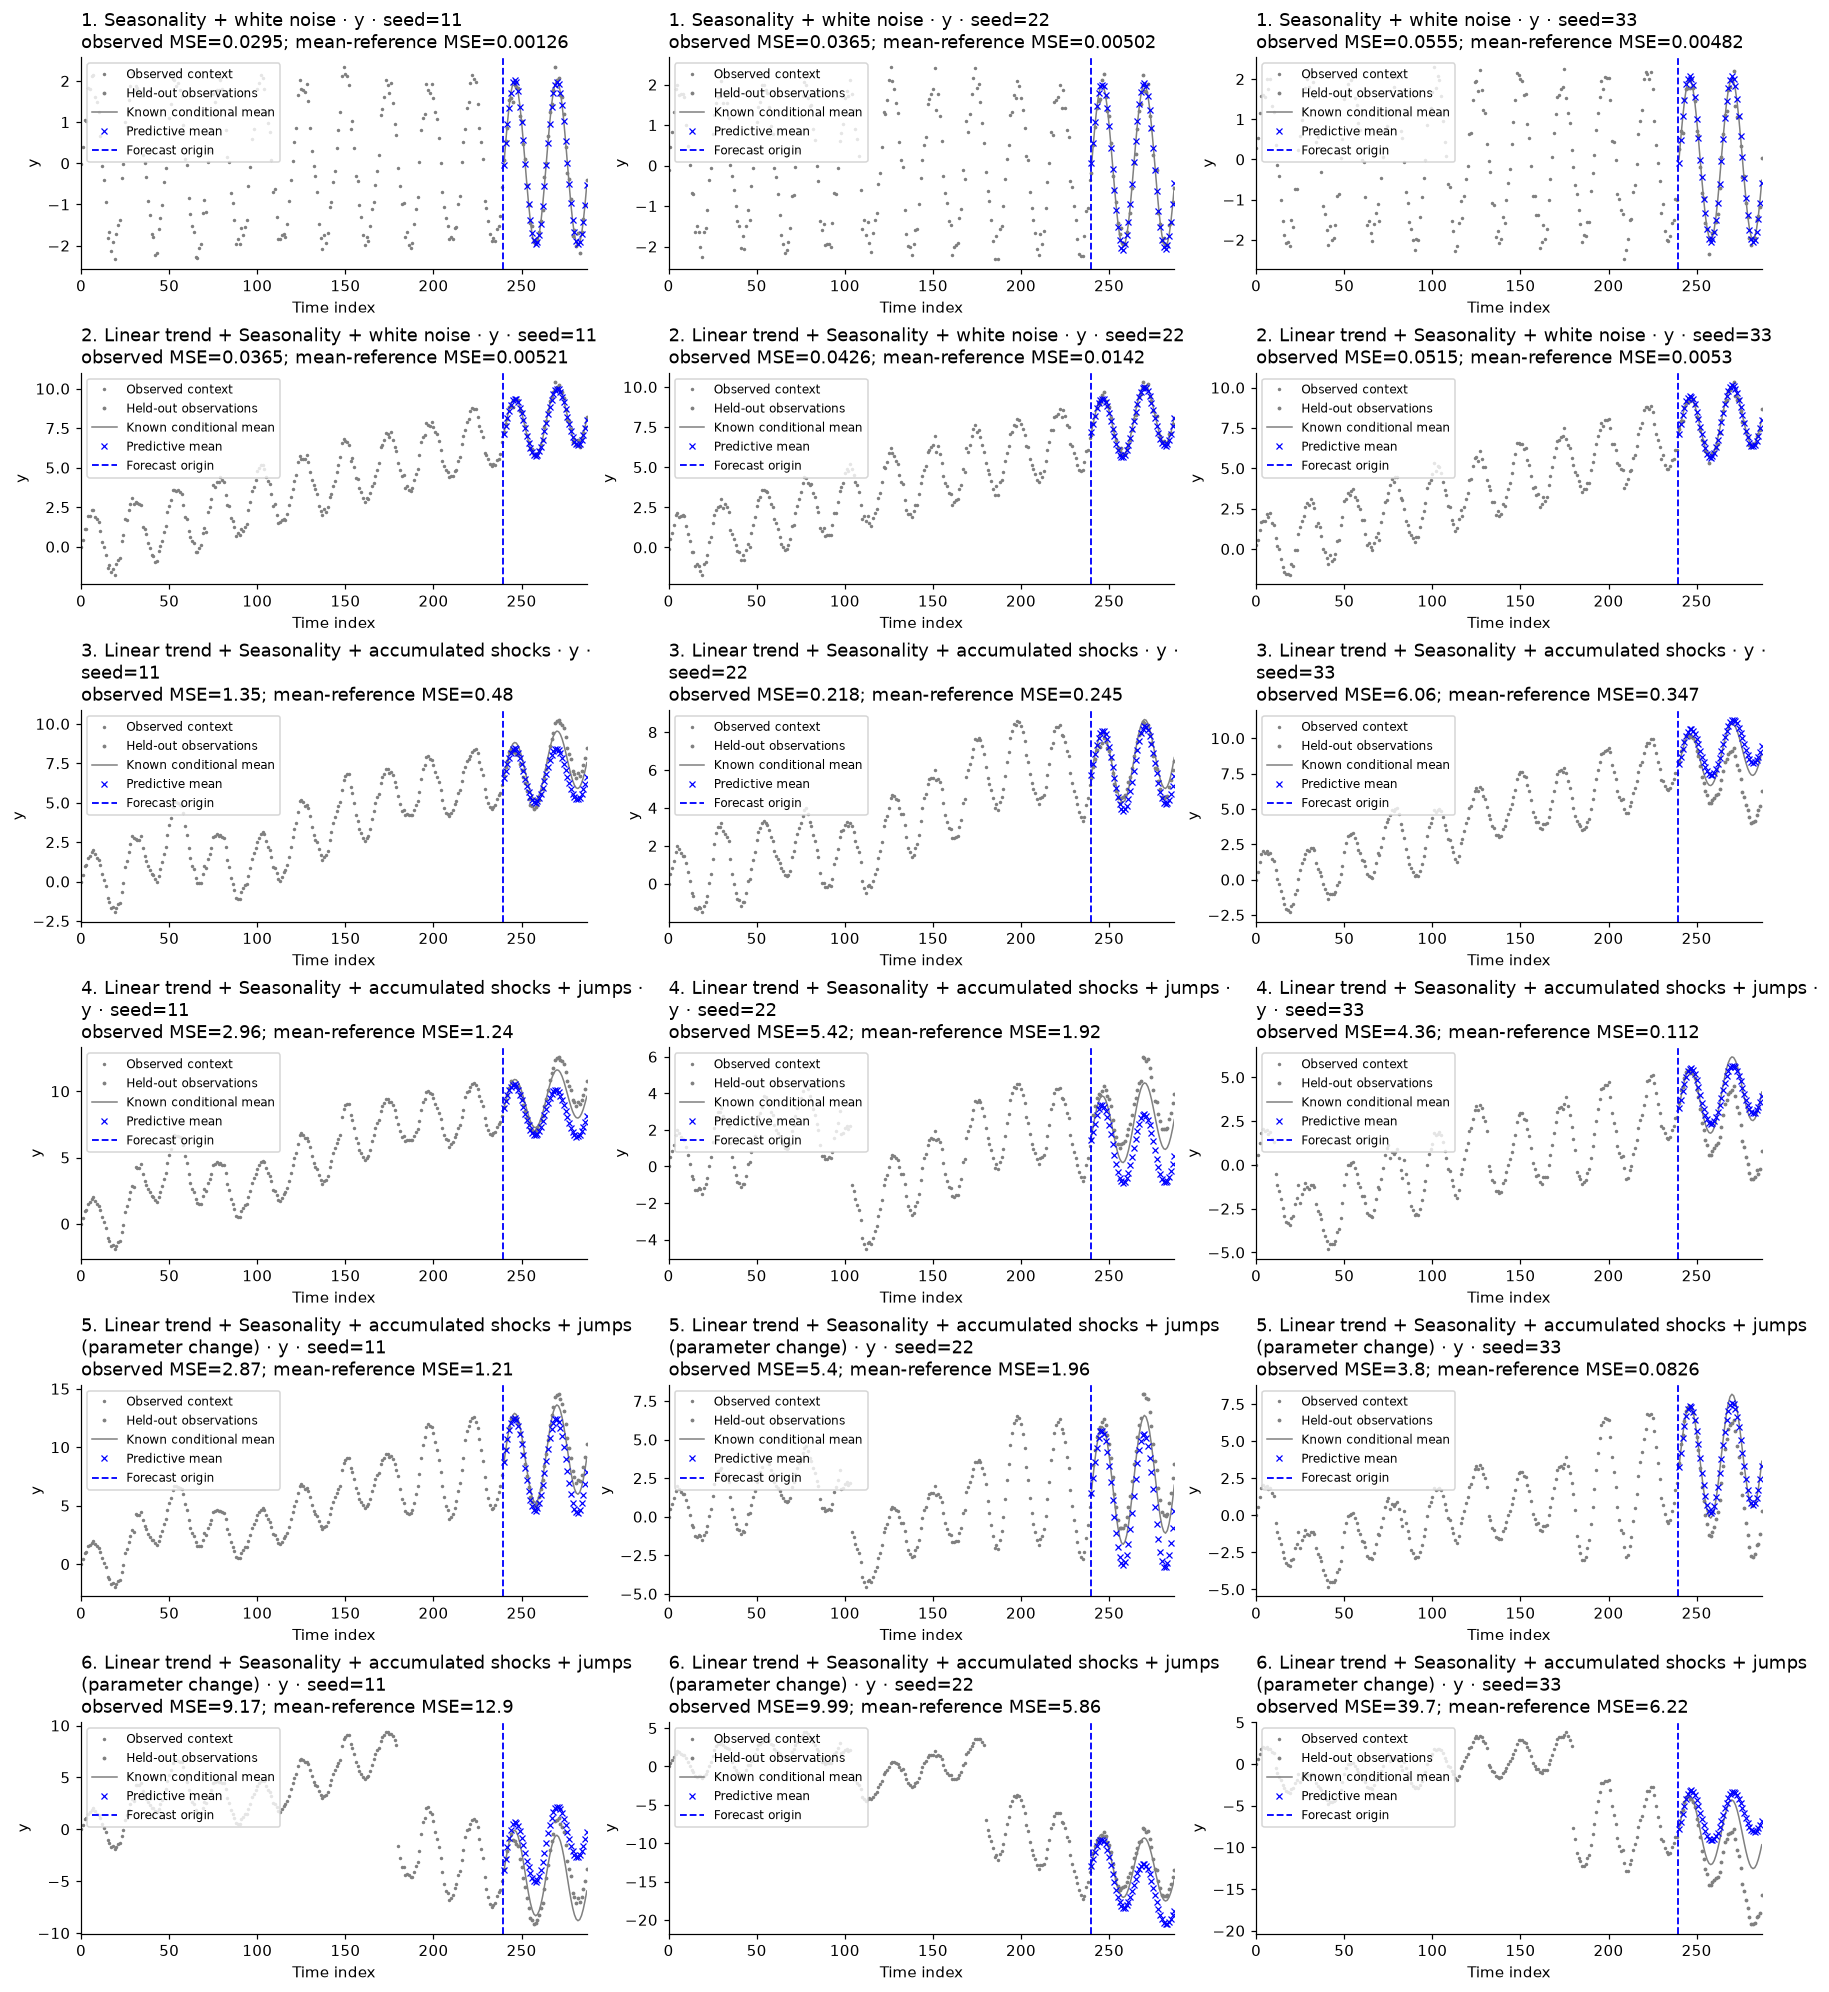

In [2]:
base = {'amplitude': 2., 'period': 24., 'sigma': .2}
ladder_specs = [
    base,
    {**base, 'slope': .03},
    {**base, 'slope': .03, 'residual': 'random_walk'},
    {**base, 'slope': .03, 'residual': 'random_walk', 'jump_rate': .04, 'jump_sigma': .9},
    {**base, 'slope': .03, 'residual': 'random_walk', 'jump_rate': .04, 'jump_sigma': .9,
     'change_point': 180, 'changes': {'amplitude': 4.}},
    {**base, 'slope': .03, 'residual': 'random_walk', 'jump_rate': .04, 'jump_sigma': .9,
     'change_point': 180, 'changes': {'amplitude': 4., 'slope': -.02, 'sigma': .4}},
]
ladder = [Scenario('composite', 240, 48, p) for p in ladder_specs]
ladder_run = lag_model.run(ladder, seeds=seeds)
ladder_figure = ladder_run.plot_forecasts(figsize=(16, 18))
for ax in ladder_figure.axes:
    heading, scores = ax.get_title(loc='left').rsplit('\n', 1)
    ax.set_title(fill(heading.replace('\n', ' '), width=60) + '\n' + scores, loc='left')
plt.show()
assert len(ladder_run.cases) == 18

## Isolate financial mechanisms, then combine them

Price, log price, and log return are different forecast targets. Here, the first pair isolates jumps in log prices; the later pair isolates jumps within hidden regimes. The final row changes the output to prices. Each panel has its own scale.

Merton uses diffusion plus compound-Poisson **log jumps**, which become multiplicative price jumps. `mu` is physical expected proportional price growth, and the log-return drift includes the jump compensator. GARCH recursively evolves variance for every future sample path. Hidden regimes are inferred from observed history; the evaluator does not use the simulator's actual hidden state.

The model sees all 240 context values; this matrix displays the final 72 plus all 24 forecast horizons, so each blue forecast cross stays distinct.

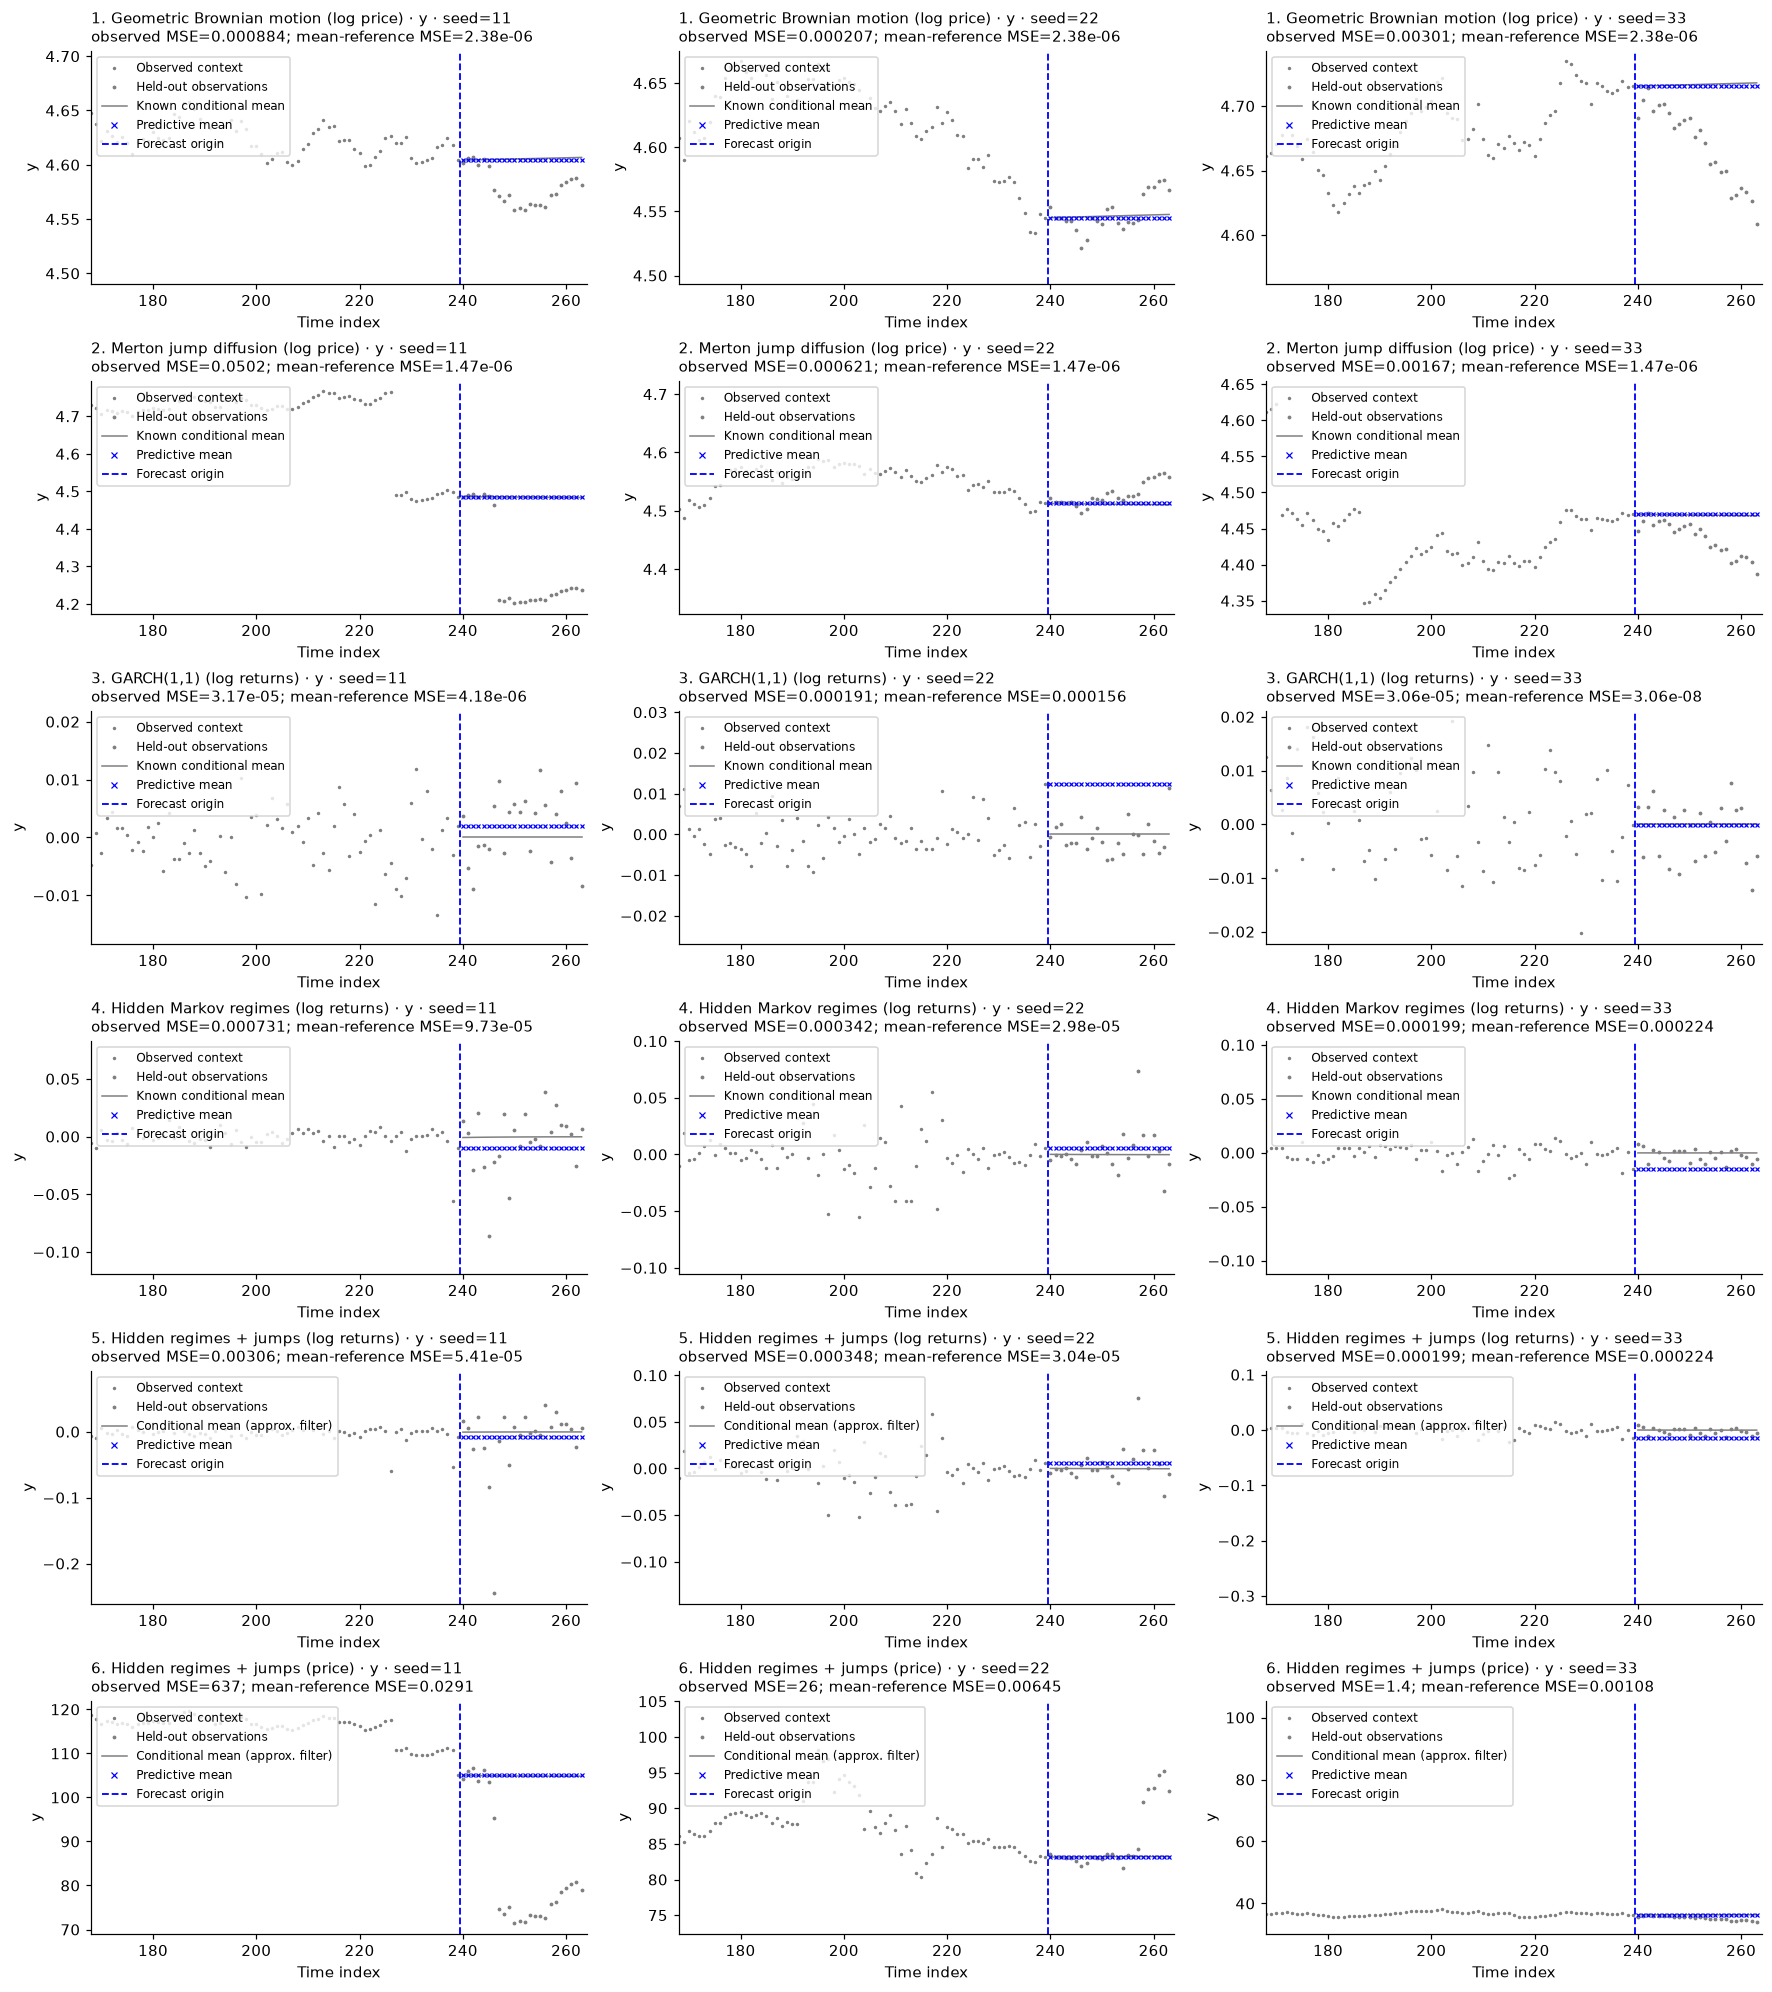

In [3]:
financial_specs = [
    {'kind': 'merton_jump_diffusion', 'parameters': {'mu': .04, 'sigma': .16, 'jump_rate': 0., 'output': 'log_price'}},
    {'kind': 'merton_jump_diffusion', 'parameters': {'mu': .04, 'sigma': .16, 'jump_rate': 6., 'jump_mean': -.05, 'jump_sigma': .12, 'output': 'log_price'}},
    {'kind': 'garch', 'parameters': {'omega': 3e-6, 'alpha': .15, 'beta': .8, 'output': 'log_return'}},
    {'kind': 'markov_switching', 'parameters': {'regime_mu': [.04, -.10], 'regime_sigma': [.10, .60], 'output': 'log_return'}},
    {'kind': 'markov_switching', 'parameters': {'regime_mu': [.04, -.10], 'regime_sigma': [.10, .60], 'regime_jump_rate': [3., 12.], 'regime_jump_mean': [0., -.06], 'regime_jump_sigma': [.03, .10], 'output': 'log_return'}},
    {'kind': 'markov_switching', 'parameters': {'regime_mu': [.04, -.10], 'regime_sigma': [.10, .60], 'regime_jump_rate': [3., 12.], 'regime_jump_mean': [0., -.06], 'regime_jump_sigma': [.03, .10], 'output': 'price'}},
]
financial = [Scenario(context_length=240, horizon=24, **spec) for spec in financial_specs]
financial_run = Pipeline(NaiveForecaster(strategy='last')).run(financial, seeds=seeds)
financial_figure = financial_run.plot_forecasts(figsize=(16, 18))
for ax in financial_figure.axes:
    ax.set_xlim(240 - 72, 240 + 24)
    for artist in ax.lines:
        if artist.get_label() == 'Predictive mean':
            artist.set_markersize(2)
plt.show()
assert len(financial_run.cases) == 18

## A price mean is not an exponentiated log-price mean

A common output-conversion error takes the mean on a transformed scale and transforms it back. That generally fails for nonlinear transformations. Compare the correct known-parameter price mean with `exp(mean log price)` using the same Merton parameters and observed history. This is an algebraic check on a declared mean output, separate from how well a fitted forecaster estimates the parameters.

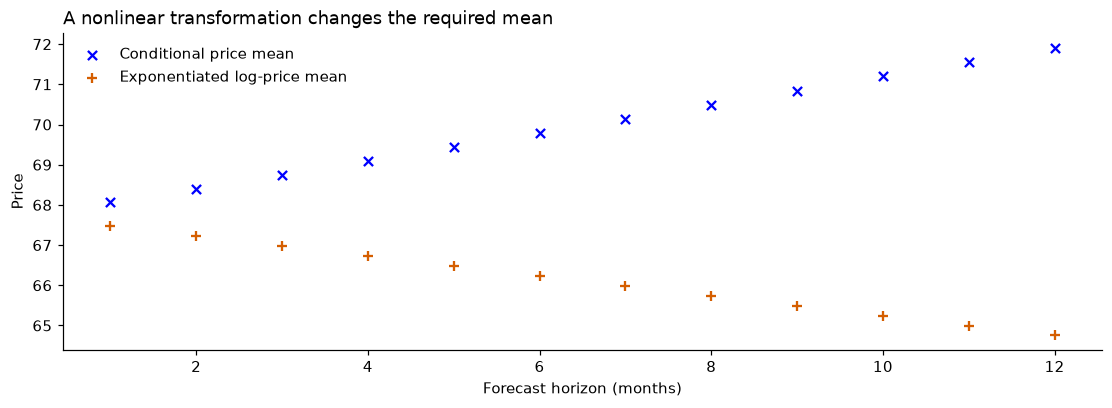

In [4]:
settings = {'mu': .06, 'sigma': .35, 'jump_rate': 2., 'jump_mean': -.08,
            'jump_sigma': .20, 'dt': 1/12}
price_case = Scenario('merton_jump_diffusion', 60, 12, {**settings, 'output': 'price'}).generate(seed=71)
log_case = Scenario('merton_jump_diffusion', 60, 12, {**settings, 'output': 'log_price'}).generate(seed=71)
np.testing.assert_allclose(np.log(price_case.task.context), log_case.task.context)
wrong_mean = np.exp(log_case.reference.mean[:, 0])
correct_mean = price_case.reference.mean[:, 0]
assert np.all(correct_mean > wrong_mean)
fig, ax = plt.subplots(figsize=(10, 3.6), layout='constrained')
h = np.arange(1, 13)
ax.scatter(h, correct_mean, marker='x', color='#0000ff', label='Conditional price mean')
ax.scatter(h, wrong_mean, marker='+', color='#d55e00', label='Exponentiated log-price mean')
ax.set(xlabel='Forecast horizon (months)', ylabel='Price', title='A nonlinear transformation changes the required mean')
ax.legend(); plt.show()

## Inspect reference capabilities before interpreting a check

Non-Gaussian references use conditional trajectory simulation and empirical marginal quantiles. The metadata records their quantile sample count and seed. Regimes plus jumps require a truncated Poisson-mixture likelihood when filtering history; their sampler is labeled approximate, and the exact covariance rank test returns `UNSUPPORTED`. A numerical likelihood tail bound is not a bound on posterior error.

In [5]:
display(pd.DataFrame([
    {'process': spec.display_name, 'reference': spec.generate(seed=11).reference.kind,
     **spec.generate(seed=11).reference.conditioning}
    for spec in financial
]).dropna(axis=1, how='all').T)

from timegym.diagnostics import covariance_dependence_check
approximate = financial[-1].generate(seed=11).reference
verdict = covariance_dependence_check(approximate, approximate.sample(64, seed=700), n_calibration=39)
assert verdict.status == 'UNSUPPORTED'
print(verdict.status, verdict.message)

,0,1,2,3,4,5
process,Geometric Brownian motion (log price),Merton jump diffusion (log price),"GARCH(1,1) (log returns)",Hidden Markov regimes (log returns),Hidden regimes + jumps (log returns),Hidden regimes + jumps (price)
reference,analytic_conditional,analytic_moments_simulation,analytic_moments_simulation,analytic_moments_simulation,analytic_moments_simulation,analytic_moments_simulation
observed_through,239,239,239,239,239,239
known_generator_parameters,True,True,True,True,True,True
future_observations_used,False,False,False,False,False,False
output_units,log_price,log_price,log_return,log_return,log_return,price
drift_convention,physical_expected_proportional_price_growth,physical_expected_proportional_price_growth,NaN,NaN,NaN,NaN
initialization,initial_price_at_index_zero,initial_price_at_index_zero,specified_initial_variance,NaN,NaN,NaN
moments_kind,NaN,analytic,analytic,analytic,analytic,analytic
sampler_kind,NaN,exact_conditional,exact_conditional,exact_conditional,approximate_conditional,approximate_conditional


UNSUPPORTED An approximate reference simulator cannot calibrate an exact conditional-law diagnostic.


## Keep the model under test interchangeable

Compare simple fitted models on **the same generated cases**. These are descriptive controls. Extend the existing native `fit/predict` contract or sklearn adapter for the forecasting method being debugged. A conditional mean error does not classify a bug.

In [6]:
candidates = {
    'Last value': Pipeline(NaiveForecaster(strategy='last')),
    'Historical mean': Pipeline(NaiveForecaster(strategy='mean')),
    'Fitted Gaussian AR(1)': Pipeline(GaussianAR1Forecaster(n_samples=64, seed=901)),
}
rows = []
for index, scenario in enumerate(financial):
    for name, candidate in candidates.items():
        report = candidate.test([scenario], seeds=range(6000, 6008))
        rows.append({'configuration': index+1, 'process': scenario.display_name,
                     'model': name, 'cases': len(report.cases),
                     'mean_reference_mse': np.mean([c.metrics['mean_reference_mse'] for c in report.cases])})
scores = pd.DataFrame(rows)
display(scores.pivot(index=['configuration', 'process'], columns='model', values='mean_reference_mse'))

report = candidates['Last value'].test([financial[-1]], seeds=[11])
replayed = report.replay_case()
assert replayed.metadata['replay']['metrics_match']
assert replayed.metadata['replay']['manifest_match']
print('The composed hidden-regime case replays from its saved configuration.')

,model,Fitted Gaussian AR(1),Historical mean,Last value
configuration,process,,,
1,Geometric Brownian motion (log price),2.548310e-04,2.247911e-02,0.000002
2,Merton jump diffusion (log price),2.087657e-03,6.672226e-02,0.000001
3,"GARCH(1,1) (log returns)",1.291974e-07,1.276571e-07,0.000027
4,Hidden Markov regimes (log returns),1.350257e-06,1.327524e-06,0.000757
5,Hidden regimes + jumps (log returns),1.548980e-06,1.515451e-06,0.000706
6,Hidden regimes + jumps (price),3.399352e+00,2.100263e+02,0.019967


The composed hidden-regime case replays from its saved configuration.


## Reserve harder tests before touching real data

Hold out **seeds, parameter regions, and combinations**, not just future points from familiar simulations. Separate contract violations, changes in predictive accuracy, and failures of calibrated probabilistic checks. Re-run the identical cases after a repair. Then freeze the pipeline before a rolling-origin evaluation on untouched real observations.

Synthetic development can itself be overfit; it does not guarantee real-market accuracy or profitability.

[Mechanisms and literature](../docs/stress-cases.md) · [Source and mathematical assumptions](14_controlled_processes.ipynb) · [Faults and repairs](23_faults_repairs_and_replay.ipynb)

Continue with [27 · Joint financial uncertainty](27_joint_financial_uncertainty.ipynb) for correlated composed processes, shared Merton jumps, CCC-GARCH and joint hidden regimes, with explicit joint-reference capabilities.